
# BHARATH BUILDS
## 21 Days to ML Engineer

# Day 11: Model Evaluation and Error Analysis

**Learning Series:** Machine Learning Engineering  
**Session Type:** Theory and Practical Implementation  
**Platform:** Google Colab  
**Dataset:** Titanic Survival Prediction Dataset

---

## 1. Introduction

Model evaluation is an essential stage of the machine learning workflow. Training a model is not enough; we must evaluate its performance on unseen data, understand its prediction errors, and determine whether it is suitable for the problem.

In this session, we will explore important classification evaluation metrics, compare multiple machine learning models, analyze incorrect predictions, and prepare a structured model evaluation report.

The primary focus is to understand not only how well a model performs, but also where it fails and how its performance should be interpreted.

## 2. Theoretical Concepts Covered

The following concepts are covered in the theoretical session:

1. **Model Evaluation**
   - Importance of evaluating machine learning models.
   - Generalization to unseen data.
   - Training, validation, and test data.

2. **Confusion Matrix**
   - True Positive (TP).
   - True Negative (TN).
   - False Positive (FP).
   - False Negative (FN).

3. **Classification Evaluation Metrics**
   - Accuracy.
   - Precision.
   - Recall.
   - F1-score.

4. **False Positives and False Negatives**
   - Understanding different types of classification errors.
   - Interpreting their impact in real-world applications.

5. **Decision Threshold**
   - Converting predicted probabilities into class labels.
   - Understanding the relationship between thresholds, precision, and recall.

6. **ROC Curve and ROC-AUC**
   - True Positive Rate (TPR).
   - False Positive Rate (FPR).
   - Evaluating model ranking performance across thresholds.

7. **Model Comparison**
   - Comparing candidate models using appropriate evaluation metrics.
   - Selecting models based on validation performance and problem requirements.

8. **Error Analysis**
   - Identifying incorrect predictions.
   - Investigating model failure patterns.
   - Understanding model limitations.

9. **Regression Evaluation Metrics**
   - Mean Absolute Error (MAE).
   - Root Mean Squared Error (RMSE).
   - Coefficient of Determination (R²).

10. **Model Evaluation Engineering Pipeline**
    - Prediction generation.
    - Metric calculation.
    - Model comparison.
    - Error investigation.
    - Reporting and documentation.

## 3. Practical Implementation

In this notebook, we will implement a complete model evaluation workflow using Python and Scikit-learn.

The practical session includes:

1. Importing the required libraries.
2. Loading and preparing the Titanic dataset.
3. Selecting input features and the target variable.
4. Splitting the data into training, validation, and test sets.
5. Building preprocessing pipelines for numerical and categorical features.
6. Training multiple classification models.
7. Comparing models using stratified cross-validation.
8. Evaluating model performance on validation data.
9. Creating a model comparison table using classification metrics.
10. Visualizing the confusion matrix.
11. Comparing ROC curves and ROC-AUC scores.
12. Investigating decision thresholds using validation data.
13. Inspecting incorrectly predicted examples.
14. Preparing a model evaluation report.
15. Saving evaluation results as CSV files.

## 4. Dataset Description

**Dataset Name:** Titanic Survival Prediction Dataset

The Titanic dataset contains passenger information and survival outcomes. It will be used to demonstrate binary classification and model evaluation.

### Target Variable

The target variable is `survived`.

- `0`: Passenger did not survive.
- `1`: Passenger survived.

### Selected Input Features

| Feature | Description |
|---|---|
| `pclass` | Passenger ticket class |
| `sex` | Passenger gender |
| `age` | Passenger age |
| `sibsp` | Number of siblings or spouses aboard |
| `parch` | Number of parents or children aboard |
| `fare` | Passenger fare |
| `embarked` | Port of embarkation |

The dataset contains both numerical and categorical features. Missing values and categorical variables will be handled through a preprocessing pipeline.

The dataset will be loaded using Scikit-learn's OpenML interface.

## 5. Tools and Technologies

The following tools and libraries will be used:

- **Google Colab:** Cloud-based notebook environment.
- **Python:** Programming language for implementation.
- **Pandas:** Data manipulation and tabular results.
- **NumPy:** Numerical operations.
- **Matplotlib:** Data visualization.
- **Seaborn:** Confusion matrix visualization.
- **Scikit-learn:** Data preprocessing, model training, cross-validation, and evaluation metrics.

### Machine Learning Algorithms

The following classification algorithms will be compared:

1. Logistic Regression.
2. K-Nearest Neighbors (KNN).
3. Decision Tree.
4. Support Vector Machine (SVM).

## 6. Evaluation Metrics

The candidate models will be evaluated using the following metrics:

| Metric | Purpose |
|---|---|
| Accuracy | Measures overall prediction correctness |
| Precision | Measures the reliability of positive predictions |
| Recall | Measures the proportion of actual positive cases identified |
| F1-score | Balances precision and recall |
| ROC-AUC | Measures ranking discrimination across thresholds |

The Titanic dataset defines survival as the positive class. Therefore, recall measures how many actual survivors are correctly identified by the model.

Model selection will use validation performance. The test set will remain separate until final evaluation.

## 7. Objectives of Day 11

By the end of this session, we aim to:

1. Understand the importance of model evaluation.
2. Interpret a confusion matrix and its four outcomes.
3. Calculate and compare classification evaluation metrics.
4. Understand false positives and false negatives.
5. Analyze the impact of decision thresholds.
6. Interpret ROC curves and ROC-AUC.
7. Compare multiple machine learning models.
8. Identify and investigate incorrect predictions.
9. Understand the importance of data preprocessing and leakage prevention.
10. Generate a structured model evaluation report.
11. Save evaluation results for documentation and portfolio development.

## 8. Expected Deliverables

The practical session will produce:

- A completed Google Colab notebook.
- Cross-validation comparison results.
- Validation performance results.
- Final test evaluation results.
- Decision threshold comparison results.
- Incorrect prediction analysis.
- A model evaluation report.

## 9. Engineering Workflow

The workflow followed in this session is:

**Prepare Data → Train Models → Evaluate → Compare → Analyze Errors → Document Results**

The objective is not simply to obtain a high evaluation score. It is to understand model performance, investigate its limitations, and make evidence-based decisions about model suitability.

## 10. Key Takeaway

A reliable machine learning engineer does not evaluate a model using accuracy alone. Model evaluation requires appropriate metrics, careful validation, error analysis, and a clear understanding of the problem's requirements.

**Day 11 Principle: Evaluate, Compare, Analyze Errors, Improve, and Document.**

---

**Created by Bharath Builds**  
**21 Days to ML Engineer | Day 11**


Step 1 — Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

# Load Titanic dataset from OpenML
from sklearn.datasets import fetch_openml

titanic = fetch_openml(
    name="titanic",
    version=1,
    as_frame=True
)

df = titanic.frame

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1309, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


Step 2: prepare the features and target

In [10]:
target="survived"

features_colums=["pclass","sex","age","sibsp","parch","fare","embarked"]
X=df[features_colums].copy()
y=pd.to_numeric(df[target],errors="coerce")

valid_rows=y.notna()

X=X[valid_rows]
y=y[valid_rows]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())


Features shape: (1309, 7)
Target shape: (1309,)
survived
0    809
1    500
Name: count, dtype: int64


Step 4 — Split training, validation and test data

In [15]:
X_train_full,X_test,y_train_full,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train,X_val,y_train,y_val=train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

print("Training set shape:", X_train.shape)
print("Validation set shape:", X_val.shape)
print("Test set shape:", X_test.shape)

Training set shape: (785, 7)
Validation set shape: (262, 7)
Test set shape: (262, 7)


step 5: preprocessing pipeline

In [17]:
numeric_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


Step 6 — Prepare four candidate models

In [18]:
models={
    "Logistic Regression":Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(random_state=42))
    ]),

    "K-Nearest Neighbors":Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier())
    ]),

    "Decision Tree":Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]),

    "Support Vector Machine":Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", SVC(random_state=42))
    ])
}

print("Candidate models created!")

for name in models:
  print(name)




Candidate models created!
Logistic Regression
K-Nearest Neighbors
Decision Tree
Support Vector Machine


step 7:compare models using cross validation

In [21]:
scoring={
    "accuracy":"accuracy",
    "precision":"precision",
    "recall":"recall",
    "f1":"f1",
    "roc_auc":"roc_auc"
}

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

cv_results=[]
for name,model in models.items():
  scores=cross_validate(
      model,
      X_train_full,
      y_train_full,
      cv=cv,
      scoring=scoring
  )
  cv_results.append({
      "model":name,
      "accuracy":scores["test_accuracy"].mean(),
      "precision":scores["test_precision"].mean(),
      "recall":scores["test_recall"].mean(),
      "f1":scores["test_f1"].mean(),
      "roc_auc:":scores["test_roc_auc"].mean()
  })

cv_results=pd.DataFrame(cv_results)
display(cv_results)


,model,accuracy,precision,recall,f1,roc_auc:
0,Logistic Regression,0.787036,0.740191,0.6875,0.710979,0.834770
1,K-Nearest Neighbors,0.786047,0.736307,0.6925,0.710617,0.821018
2,Decision Tree,0.755489,0.692657,0.6550,0.672103,0.743423
3,Support Vector Machine,0.799426,0.765410,0.6925,0.724580,0.827287


step 8: fit the models and compare the performance

In [29]:
fitted_models = {}
validation_results = []
validation_probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_val_pred = model.predict(X_val)
    # y_val_prob = model.predict_proba(X_val)[:,1]

    fitted_models[name] = model
    validation_probabilities[name] = y_val_prob

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_val_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob)
    })

validation_table = pd.DataFrame(validation_results)

display(
    validation_table.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.790,0.747,0.680,0.712,0.746
1,K-Nearest Neighbors,0.805,0.763,0.710,0.736,0.746
2,Decision Tree,0.748,0.677,0.650,0.663,0.746
3,Support Vector Machine,0.786,0.775,0.620,0.689,0.746


Step 9 — Select a model and build the final test comparison

In [33]:
selected_name = validation_table.loc[
    validation_table["Recall"].idxmax(),
    "Model"
]

print("Selected using validation recall:", selected_name)

test_results = []
test_predictions = {}
test_probabilities = {}

for name, model in fitted_models.items():
    y_test_pred = model.predict(X_test)
    # y_test_prob = model.predict_proba(X_test)[:, 1]

    test_predictions[name] = y_test_pred
    test_probabilities[name] = y_test_prob

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_test_prob)
    })

test_table = pd.DataFrame(test_results)

display(
    test_table.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
)

Selected using validation recall: K-Nearest Neighbors


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.798,0.758,0.690,0.723,0.741
1,K-Nearest Neighbors,0.802,0.750,0.720,0.735,0.741
2,Decision Tree,0.744,0.663,0.670,0.667,0.741
3,Support Vector Machine,0.828,0.848,0.670,0.749,0.741


step 10 : plot confusion matrix

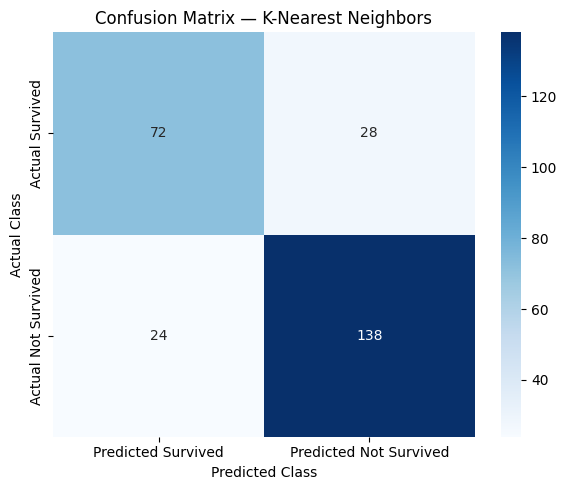

              precision    recall  f1-score   support

    Survived       0.75      0.72      0.73       100
Not Survived       0.83      0.85      0.84       162

    accuracy                           0.80       262
   macro avg       0.79      0.79      0.79       262
weighted avg       0.80      0.80      0.80       262



In [39]:
y_test_pred = test_predictions[selected_name]

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[1, 0]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Survived", "Predicted Not Survived"],
    yticklabels=["Actual Survived", "Actual Not Survived"]
)

plt.title(f"Confusion Matrix — {selected_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_test_pred,
    labels=[1, 0],
    target_names=["Survived", "Not Survived"],
    zero_division=0
))

Step 11 — Compare ROC curves

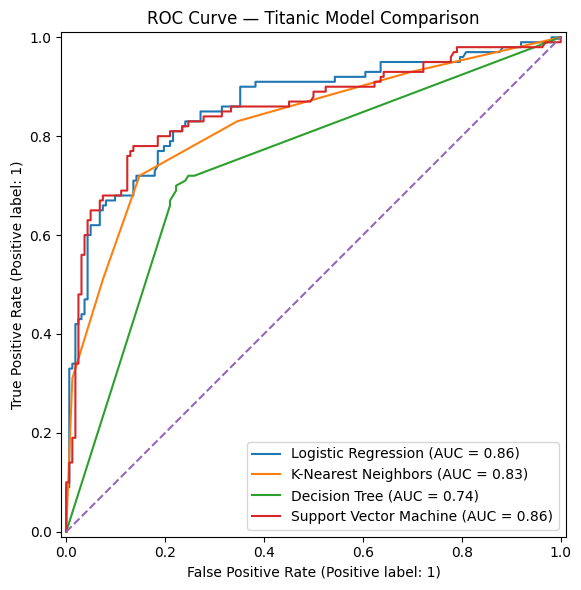

In [41]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking"
)

ax.set_title("ROC Curve — Titanic Model Comparison")
plt.tight_layout()
plt.show()

Step 12 — Understand decision thresholds

In [42]:
from sklearn.metrics import precision_recall_curve

val_prob = validation_probabilities[selected_name]

precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    val_prob
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-12)
)

best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("Threshold selected using validation F1:", round(best_threshold, 3))

threshold_results = []

for threshold in [0.30, 0.50, 0.70, best_threshold]:
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1-score": f1_score(y_val, val_pred, zero_division=0)
    })

threshold_table = pd.DataFrame(threshold_results).drop_duplicates(
    subset=["Threshold"]
)

display(
    threshold_table.style.format({
        "Threshold": "{:.3f}",
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}"
    })
)

Threshold selected using validation F1: 0.429


,Threshold,Accuracy,Precision,Recall,F1-score
0,0.300,0.744,0.649,0.720,0.682
1,0.500,0.729,0.641,0.660,0.650
2,0.700,0.748,0.677,0.650,0.663
3,0.429,0.744,0.649,0.720,0.682


Step 13 — Perform error analysis

In [44]:
y_test_prob = test_probabilities[selected_name]
y_test_pred = test_predictions[selected_name]

error_df = X_test.copy()

error_df["Actual"] = y_test
error_df["Predicted"] = y_test_pred
error_df["Predicted_Survival_Probability"] = y_test_prob

error_df["Error_Type"] = np.select(
    [
        (error_df["Actual"] == 1) & (error_df["Predicted"] == 0),
        (error_df["Actual"] == 0) & (error_df["Predicted"] == 1)
    ],
    [
        "False Negative",
        "False Positive"
    ],
    default="Correct"
)

wrong_predictions = error_df[
    error_df["Actual"] != error_df["Predicted"]
].copy()

print("Total test samples:", len(X_test))
print("Incorrect predictions:", len(wrong_predictions))

display(wrong_predictions.head(10))

Total test samples: 262
Incorrect predictions: 52


,pclass,sex,age,sibsp,parch,fare,embarked,Actual,Predicted,Predicted_Survival_Probability,Error_Type
20,1,male,37.0,1,1,52.5542,S,1,0,1.000000,False Negative
1263,3,male,11.5,1,1,14.5000,S,0,1,1.000000,False Positive
742,3,male,45.0,0,0,8.0500,S,1,0,0.000000,False Negative
889,3,male,26.0,0,0,7.7750,S,1,0,0.000000,False Negative
1024,3,male,25.0,0,0,7.6500,S,0,1,1.000000,False Positive
906,3,male,27.0,0,0,7.8542,S,0,1,0.000000,False Positive
596,2,male,31.0,0,0,13.0000,S,1,0,0.000000,False Negative
959,3,male,32.0,0,0,7.9250,S,0,1,1.000000,False Positive
37,1,male,NaN,0,0,26.5500,S,1,0,0.333333,False Negative
1254,3,male,25.0,0,0,0.0000,S,1,0,0.000000,False Negative


## Error Analysis — Key Interpretations

- **Total Errors:** Out of 262 test samples, 52 predictions were incorrect, showing that the model still has room for improvement.
- **False Negatives:** The model predicted that some passengers would not survive, even though they actually survived.
- **False Positives:** The model predicted that some passengers would survive, even though they did not.
- **Feature Patterns:** Passenger class, gender, age, fare, and family details may help explain prediction errors, but need further analysis.
- **Prediction Confidence:** Some wrong predictions have extreme probability scores, so we should verify how survival probabilities were calculated.
- **Key Learning:** Error analysis helps us understand where the model fails instead of relying only on accuracy.
- **Next Step:** Investigate misclassified cases and improve the model using validation-based tuning and feature analysis.

In [46]:
selected_test_row = test_table[
    test_table["Model"] == selected_name
].iloc[0]

print("DAY 11 — MODEL EVALUATION REPORT")
print("=" * 45)

print("Dataset: Titanic Survival Prediction")
print("Selected model:", selected_name)
print("Selection rule: Highest validation recall")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nFinal held-out test metrics:")
for metric in [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
]:
    print(f"{metric}: {selected_test_row[metric]:.3f}")

print("\nValidation-selected threshold:", round(best_threshold, 3))
print("Incorrect default-threshold test predictions:",
      len(wrong_predictions))

print("\nLimitations:")
print("- Results depend on the data split and selected features.")
print("- Threshold was selected using validation data.")
print("- Historical Titanic data may contain biases.")
print("- This is an educational classification exercise.")

DAY 11 — MODEL EVALUATION REPORT
Dataset: Titanic Survival Prediction
Selected model: K-Nearest Neighbors
Selection rule: Highest validation recall
Training samples: 785
Validation samples: 262
Test samples: 262

Final held-out test metrics:
Accuracy: 0.802
Precision: 0.750
Recall: 0.720
F1-score: 0.735
ROC-AUC: 0.741

Validation-selected threshold: 0.429
Incorrect default-threshold test predictions: 52

Limitations:
- Results depend on the data split and selected features.
- Threshold was selected using validation data.
- Historical Titanic data may contain biases.
- This is an educational classification exercise.


Step 15 — Save the results as CSV files

In [54]:
import pandas as pd

# Convert dictionaries to DataFrames when necessary
if isinstance(cv_table, dict):
    cv_table = pd.DataFrame(cv_table)

if isinstance(validation_table, dict):
    validation_table = pd.DataFrame(validation_table)

if isinstance(test_table, dict):
    test_table = pd.DataFrame(test_table)

if isinstance(threshold_table, dict):
    threshold_table = pd.DataFrame(threshold_table)

if isinstance(wrong_predictions, dict):
    wrong_predictions = pd.DataFrame(wrong_predictions)

# Save all result files
cv_table.to_csv("day11_cross_validation_results.csv", index=False)
validation_table.to_csv("day11_validation_results.csv", index=False)
test_table.to_csv("day11_test_results.csv", index=False)
threshold_table.to_csv("day11_threshold_comparison.csv", index=False)
wrong_predictions.to_csv("day11_error_analysis.csv", index=True)

print("All Day 11 result files saved successfully!")

from google.colab import files

for filename in [
    "day11_cross_validation_results.csv",
    "day11_validation_results.csv",
    "day11_test_results.csv",
    "day11_threshold_comparison.csv",
    "day11_error_analysis.csv"
]:
    files.download(filename)

All Day 11 result files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>